# Worksheet: การกลับภาพ (Image Flipping)

ใบงานนี้ใช้ฟังก์ชันชุดเดียวกับทั้ง **ภาพระดับเทา** และ **ภาพสี RGB** เพื่อให้เห็นว่าการกลับภาพคือการย้ายตำแหน่งพิกเซล ส่วนค่าความเข้มหรือค่าสีของพิกเซลไม่เปลี่ยน

เมื่อจบใบงาน นักศึกษาจะสามารถ

- อธิบายตำแหน่งพิกเซลด้วยแถว `y` และคอลัมน์ `x`
- เขียนโปรแกรมกลับภาพซ้าย–ขวา บน–ล่าง และทั้งสองทิศ
- ใช้โค้ดเดียวกันกับอาร์เรย์ภาพ 2 มิติและ 3 มิติ
- สลับแถวกับคอลัมน์ของภาพ (transpose) และตรวจคำตอบด้วย NumPy/OpenCV

In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1) ภาพในรูปอาร์เรย์

- ภาพระดับเทาเก็บเป็นอาร์เรย์ขนาด `(H, W)` แต่ละพิกเซลมีค่าความเข้มหนึ่งค่า
- ภาพสี RGB เก็บเป็นอาร์เรย์ขนาด `(H, W, 3)` พิกเซลหนึ่งจุดมีค่า `[R, G, B]`
- `H` คือจำนวนแถว (ความสูง) และ `W` คือจำนวนคอลัมน์ (ความกว้าง)
- ตำแหน่ง `image[y, x]` หมายถึงพิกเซลแถว `y` คอลัมน์ `x` โดยเริ่มนับจาก 0

> OpenCV อ่านภาพสีเป็นลำดับ BGR แต่ Matplotlib แสดงภาพเป็น RGB จึงต้องแปลงสีก่อนแสดงผล

In [27]:
def show_image(image, title=""):
    """แสดงภาพระดับเทาหรือภาพสี RGB"""
    plt.figure(figsize=(4, 4))
    if image.ndim == 2:
        plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        plt.imshow(image) #RGB
    plt.title(title)
    plt.axis("off")
    plt.show()


def show_images(images, titles):
    """แสดงหลายภาพในหนึ่งแถวเพื่อเปรียบเทียบ"""
    plt.figure(figsize=(4 * len(images), 4))
    for index, (image, title) in enumerate(zip(images, titles), start=1): #enumurate defult start = 0 Memory it to Final Test
        plt.subplot(1, len(images), index)
        if image.ndim == 2:  #ndim = check dimension
            plt.imshow(image, cmap="gray", vmin=0, vmax=255)
        else:
            plt.imshow(image)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## 2) อ่านภาพตัวอย่าง

ใช้ `IMREAD_GRAYSCALE` เพื่ออ่านภาพระดับเทา ส่วนภาพสีต้องแปลงจาก BGR เป็น RGB ก่อนนำไปแสดงด้วย Matplotlib

ภาพระดับเทา: (512, 512) uint8
ภาพสี RGB  : (256, 256, 3) uint8


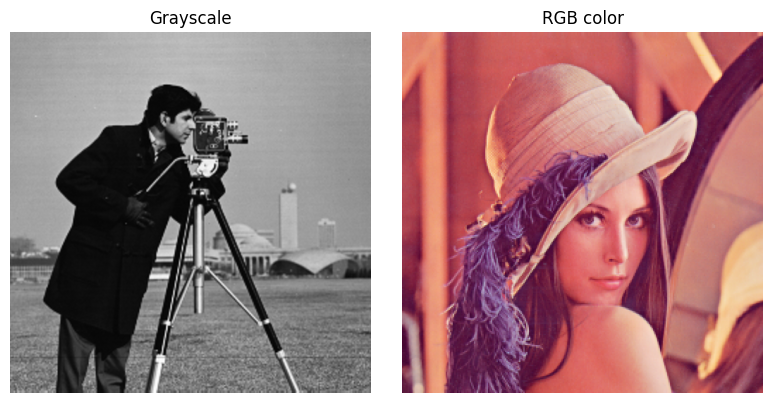

In [28]:
gray_image = cv2.imread("../images/cameraman.png", cv2.IMREAD_GRAYSCALE)
color_bgr = cv2.imread("../images/lena_color_256.png", cv2.IMREAD_COLOR)

if gray_image is None or color_bgr is None:
    raise FileNotFoundError("ไม่พบภาพตัวอย่างในโฟลเดอร์ ./images")

color_image = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2RGB)

print("ภาพระดับเทา:", gray_image.shape, gray_image.dtype)
print("ภาพสี RGB  :", color_image.shape, color_image.dtype)
show_images(
    [gray_image, color_image],
    ["Grayscale", "RGB color"],
)

## 3) ทดลองด้วยอาร์เรย์ขนาดเล็ก

ก่อนใช้ภาพจริง ลองดูอาร์เรย์ 3 แถว 4 คอลัมน์ ตัวเลขแต่ละตัวแทนค่าพิกเซลหนึ่งตำแหน่ง ทำให้ติดตามการย้ายตำแหน่งได้ง่าย

In [29]:
small_image = np.arange(1, 13).reshape(3, 4)  #arange create array 1 dim(12,)  and reshape(3,4) -> 3 rows 4 cols
print(small_image)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]


In [30]:
y = small_image[:,::-1]  # ::-1 สัญลักษณ์การสลับ
x = small_image[::-1,:2]
print(y)
print(x)

[[ 4  3  2  1]
 [ 8  7  6  5]
 [12 11 10  9]]
[[ 9 10]
 [ 5  6]
 [ 1  2]]


## 4) การกลับภาพ

ให้ภาพมีความสูง `H` และความกว้าง `W` ค่าของภาพผลลัพธ์ที่ตำแหน่ง `(y, x)` มาจากตำแหน่งต่อไปนี้

| ทิศทาง | ตำแหน่งในภาพต้นฉบับ | ผลที่เห็น |
|---|---|---|
| ซ้าย–ขวา (`horizontal`) | `(y, col - 1 - x)` | เหมือนส่องกระจก |
| บน–ล่าง (`vertical`) | `(row - 1 - y, x)` | ภาพกลับหัว |
| ทั้งสองทิศ (`both`) | `(row - 1 - y, col - 1 - x)` | เทียบเท่าหมุน 180° |

จุดสำคัญคือภาพสีไม่ต้องเขียนลูปเพิ่มสำหรับช่องสี เมื่อใช้ `image[source_y, source_x]` NumPy จะนำค่าทั้ง `[R, G, B]` มาให้โดยอัตโนมัติ

In [31]:
# Old method
import cv2
img = cv2.imread('../images/cameraman.png',0)
out = np.zeros_like(img,dtype=np.uint8)
row , col = img.shape[:2] # need two element of shape

for y in range(row):
    for x in range(col):
        out[y,x] = img[y,col-1-x] # but python can write out[y,x] = img[y,col-1-x] do 3 spades same out[y,x,:] = img[y,col-1-x,:]
        # out[y,x] = img[row-1-y,x]  # ทำได้ทีละ flip หรือทำได้ทีละ method จะทำแนวไหนได้method ละแนว

In [ ]:
def flip_image(image, direction):
    """กลับภาพด้วยการคัดลอกพิกเซล เหมาะกับทั้งภาพระดับเทาและภาพสี"""
    valid_directions = {"horizontal", "vertical", "both"}
    if direction not in valid_directions:
        raise ValueError(f"direction ต้องเป็นค่าใดค่าหนึ่งใน {valid_directions}")

    height, width = image.shape[:2]
    result = np.zeros_like(image) #not use empty_like

    for y in range(height):
        for x in range(width):
            yo, xo = y, x

            if direction in ("vertical", "both"):
                yo = height - 1 - y
            if direction in ("horizontal", "both"):
                xo = width - 1 - x

            result[y, x] = image[yo, xo]

    return result

In [33]:
print("ต้นฉบับ")
print(small_image)

for direction in ("horizontal", "vertical", "both"):
    print(f"\n{direction}")
    print(flip_image(small_image, direction))

ต้นฉบับ
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

horizontal


NameError: name 'np' is not defined

### ทดลองกับภาพระดับเทา

สังเกตว่ารูปร่างอาร์เรย์และชนิดข้อมูลยังเหมือนเดิม มีเพียงตำแหน่งพิกเซลที่เปลี่ยน

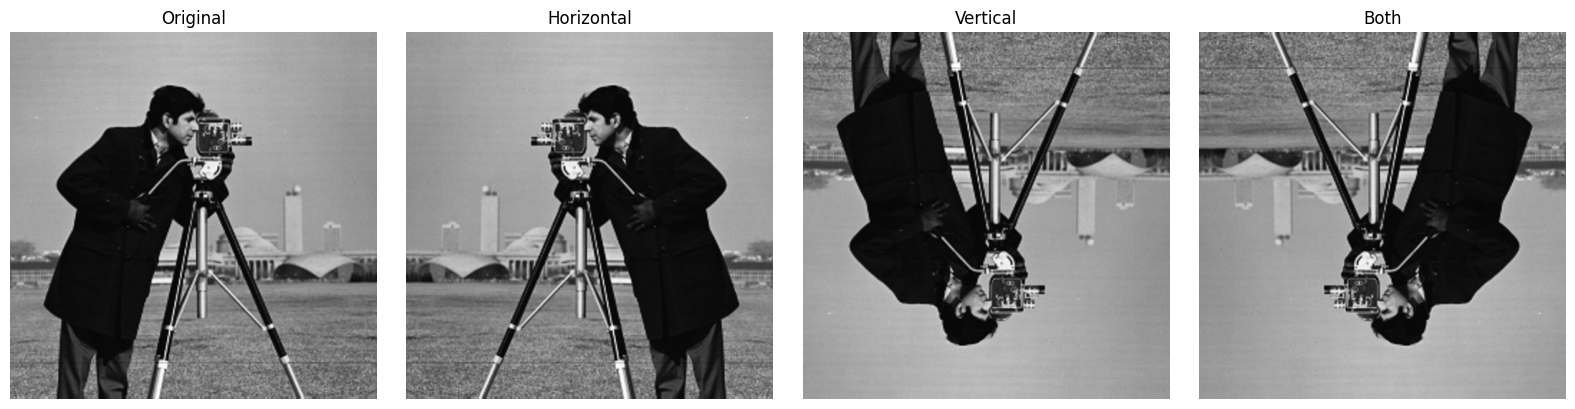

In [ ]:
gray_horizontal = flip_image(gray_image, "horizontal")
gray_vertical = flip_image(gray_image, "vertical")
gray_both = flip_image(gray_image, "both")

show_images(
    [gray_image, gray_horizontal, gray_vertical, gray_both],
    ["Original", "Horizontal", "Vertical", "Both"],
)

### ทดลองกับภาพสี

ใช้ฟังก์ชันเดิมได้ทันที เพราะ `image.shape[:2]` อ่านเฉพาะความสูงและความกว้าง และคำสั่งกำหนดค่าพิกเซลจะคัดลอกครบทั้ง 3 ช่องสี

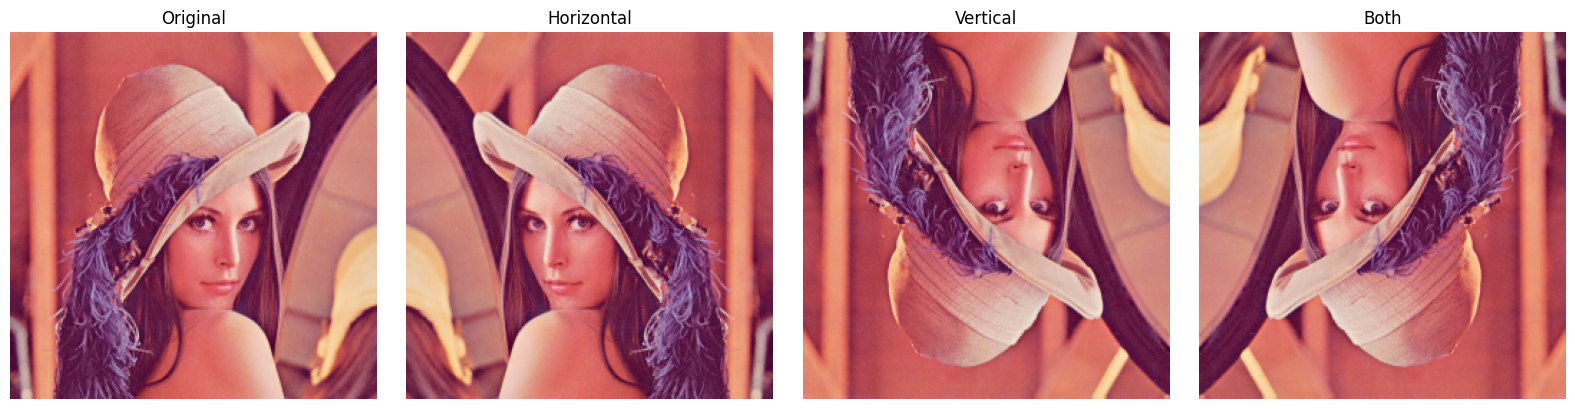

In [ ]:
color_horizontal = flip_image(color_image, "horizontal")
color_vertical = flip_image(color_image, "vertical")
color_both = flip_image(color_image, "both")

show_images(
    [color_image, color_horizontal, color_vertical, color_both],
    ["Original", "Horizontal", "Vertical", "Both"],
)

## 5) วิธีสั้นด้วย NumPy และ OpenCV

ฟังก์ชันที่เขียนเองช่วยให้เห็นหลักการย้ายพิกเซล แต่เมื่อต้องใช้งานจริงสามารถใช้คำสั่งที่สั้นกว่า

- NumPy: `image[:, ::-1]` กลับซ้าย–ขวา และ `image[::-1, :]` กลับบน–ล่าง
- OpenCV: `cv2.flip(image, 1)` กลับซ้าย–ขวา, `0` กลับบน–ล่าง และ `-1` กลับทั้งสองทิศ

การ slice ใช้ได้กับภาพสีด้วย เพราะไม่ได้ระบุแกนช่องสี

In [ ]:
# ตรวจว่าฟังก์ชันที่เขียนเองให้ผลตรงกับ NumPy และ OpenCV
assert np.array_equal(flip_image(gray_image, "horizontal"), gray_image[:, ::-1]) # horizon  np.array_equl return boolean
assert np.array_equal(flip_image(color_image, "vertical"), color_image[::-1, :])
assert np.array_equal(flip_image(color_image, "both"), cv2.flip(color_image, -1)) #cv2.filp 0 =horizon,1 = vertical, -1= both 

print("ตรวจแล้ว: ผลลัพธ์ตรงกันทุกกรณี")

ตรวจแล้ว: ผลลัพธ์ตรงกันทุกกรณี


## 6) การสลับแถวและคอลัมน์ (Transpose)

Transpose เป็นการสะท้อนภาพตามแนวทแยง โดยย้ายพิกเซลจาก `(y, x)` ไป `(x, y)` ดังนั้น

- ภาพระดับเทาเปลี่ยนจาก `(H, W)` เป็น `(W, H)`
- ภาพสีเปลี่ยนจาก `(H, W, 3)` เป็น `(W, H, 3)` ช่องสียังคงอยู่ตำแหน่งเดิม

Transpose ไม่ใช่การกลับซ้าย–ขวาหรือบน–ล่าง และไม่เท่ากับการหมุน 90° โดยตรง

In [ ]:
def transpose_image(image):
    """สลับแกนแถวและคอลัมน์ โดยไม่สลับแกนช่องสี"""
    height, width = image.shape[:2]
    new_shape = (width, height) + image.shape[2:]
    result = np.empty(new_shape, dtype=image.dtype)

    for y in range(height):
        for x in range(width):
            result[x, y] = image[y, x]

    return result

ต้นฉบับ:
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

Transpose:
 [[ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]
 [ 4  8 12]]
Grayscale: (512, 180) -> (180, 512)
RGB      : (256, 180, 3) -> (180, 256, 3)


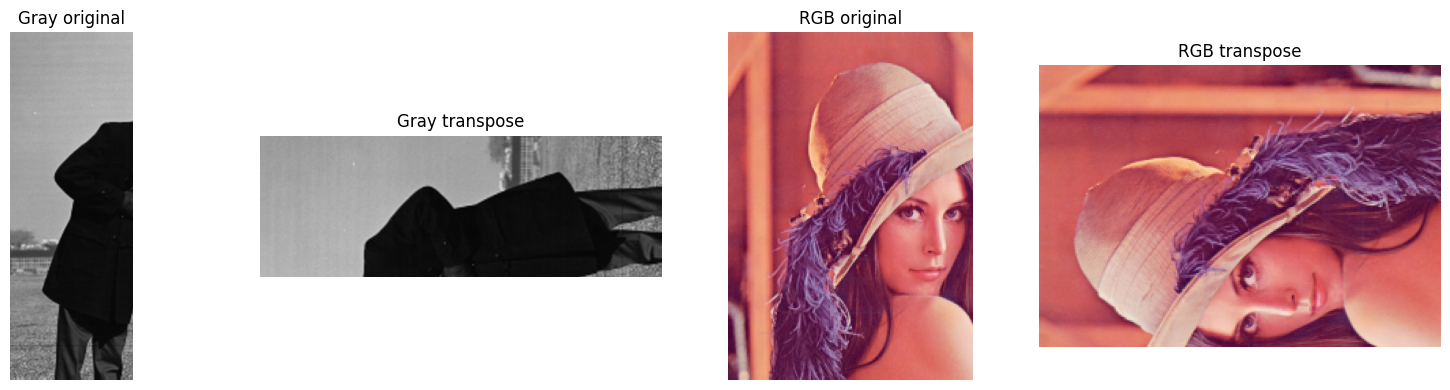

In [ ]:
print("ต้นฉบับ:\n", small_image)
print("\nTranspose:\n", transpose_image(small_image))

# ตัดภาพให้เป็นสี่เหลี่ยมผืนผ้า เพื่อให้เห็นว่าความสูงกับความกว้างสลับกัน
gray_rect = gray_image[:, :180]
color_rect = color_image[:, :180] # color image จะเอา มาทั้ง spades อยู่แล้วโดยไม่ต้องเขียน color_image[:,:180,:]

gray_transposed = transpose_image(gray_rect)
color_transposed = transpose_image(color_rect)

print("Grayscale:", gray_rect.shape, "->", gray_transposed.shape)
print("RGB      :", color_rect.shape, "->", color_transposed.shape)

show_images(
    [gray_rect, gray_transposed, color_rect, color_transposed],
    ["Gray original", "Gray transpose", "RGB original", "RGB transpose"],
)

In [ ]:
# NumPy สลับเฉพาะแกน 0 และ 1 จึงใช้ได้กับทั้งภาพระดับเทาและภาพสี
assert np.array_equal(transpose_image(gray_image), np.swapaxes(gray_image, 0, 1))
assert np.array_equal(transpose_image(color_image), np.swapaxes(color_image, 0, 1)) #np.swapaxes ใช้ transposeดีกว่า แต่ลองไปดู swapaxes เล่นๆ

print("ตรวจแล้ว: transpose_image ให้ผลตรงกับ np.swapaxes")

ตรวจแล้ว: transpose_image ให้ผลตรงกับ np.swapaxes


## 7) แบบฝึกหัด

1. เปลี่ยน `test_direction` เป็น `"vertical"` และ `"both"` แล้วอธิบายผลที่เห็น
2. เติมฟังก์ชัน `flip_with_slicing()` โดยใช้ slicing เพียงหนึ่งบรรทัดต่อทิศทาง
3. ตรวจสมบัติ: ถ้ากลับภาพทิศเดิมสองครั้ง ควรได้ภาพต้นฉบับหรือไม่ เพราะอะไร
4. ทดลอง transpose ภาพสี่เหลี่ยมผืนผ้า แล้วระบุ shape ก่อนและหลัง

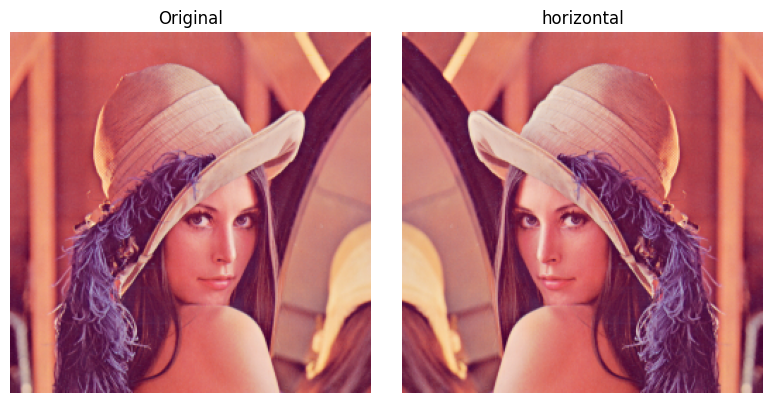

In [ ]:
# แบบฝึกหัด 1
test_direction = "horizontal"
test_image = flip_image(color_image, test_direction)
show_images([color_image, test_image], ["Original", test_direction])

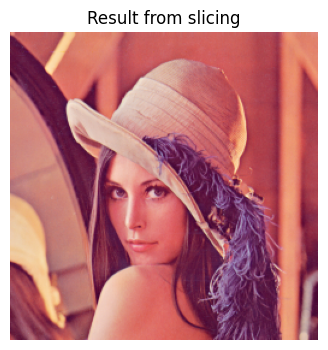

In [ ]:
# แบบฝึกหัด 2: เติมส่วน TODO
def flip_with_slicing(image, direction):
    if direction == "horizontal":
        result = image[:, ::-1]
    elif direction == "vertical":
        result = image[::-1, :]
    elif direction == "both":
        result = image[::-1, ::-1]
    else:
        raise ValueError("direction ไม่ถูกต้อง")
    return result


# ลองเปลี่ยน color_image เป็น gray_image
exercise_result = flip_with_slicing(color_image, "horizontal")
show_image(exercise_result, "Result from slicing")

In [ ]:
# แบบฝึกหัด 3: กลับภาพทิศเดิมสองครั้ง
flipped_twice = flip_image(
    flip_image(gray_image, "horizontal"),
    "horizontal",
)

print("กลับสองครั้งได้ภาพเดิม:", np.array_equal(gray_image, flipped_twice))

กลับสองครั้งได้ภาพเดิม: True


## 8) ใช้ฟังก์ชันสำเร็จรูปของ OpenCV

เมื่อต้องทำงานจริง ใช้ `cv2.flip(image, flipCode)` ได้โดยไม่ต้องเขียนลูปเอง

| `flipCode` | การทำงาน |
|---:|---|
| `1` | กลับซ้าย–ขวา |
| `0` | กลับบน–ล่าง |
| `-1` | กลับทั้งสองทิศ |

คำสั่งนี้ใช้ได้เหมือนกันกับภาพระดับเทาและภาพสี เพราะ OpenCV ย้ายพิกเซลพร้อมค่าทุกช่องสี

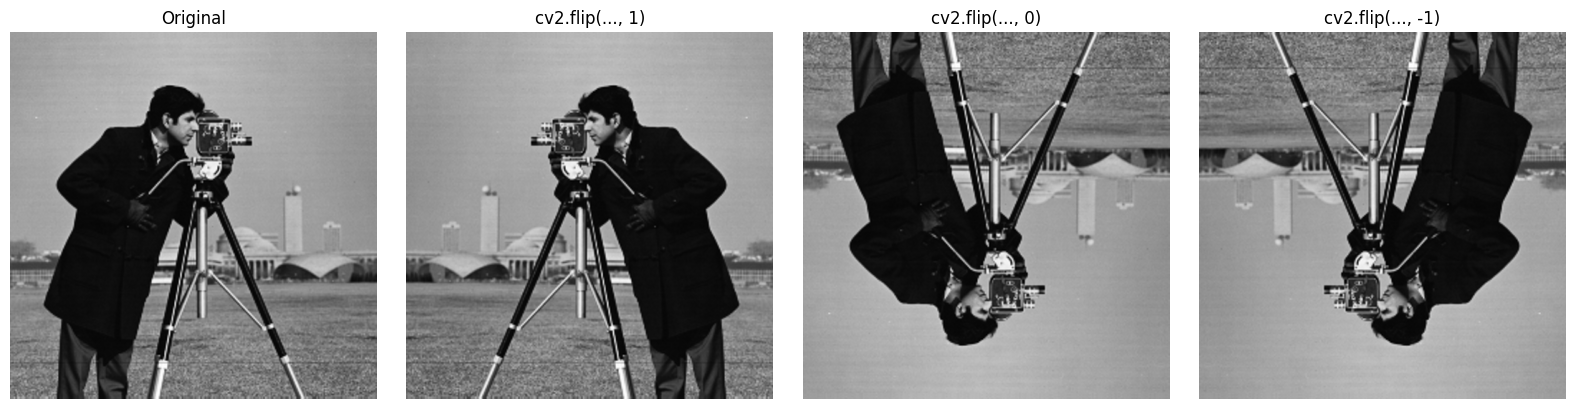

In [ ]:
# ตัวอย่าง cv2.flip() กับภาพระดับเทา
cv_gray_horizontal = cv2.flip(gray_image, 1)
cv_gray_vertical = cv2.flip(gray_image, 0)
cv_gray_both = cv2.flip(gray_image, -1)

show_images(
    [gray_image, cv_gray_horizontal, cv_gray_vertical, cv_gray_both],
    ["Original", "cv2.flip(..., 1)", "cv2.flip(..., 0)", "cv2.flip(..., -1)"],
)

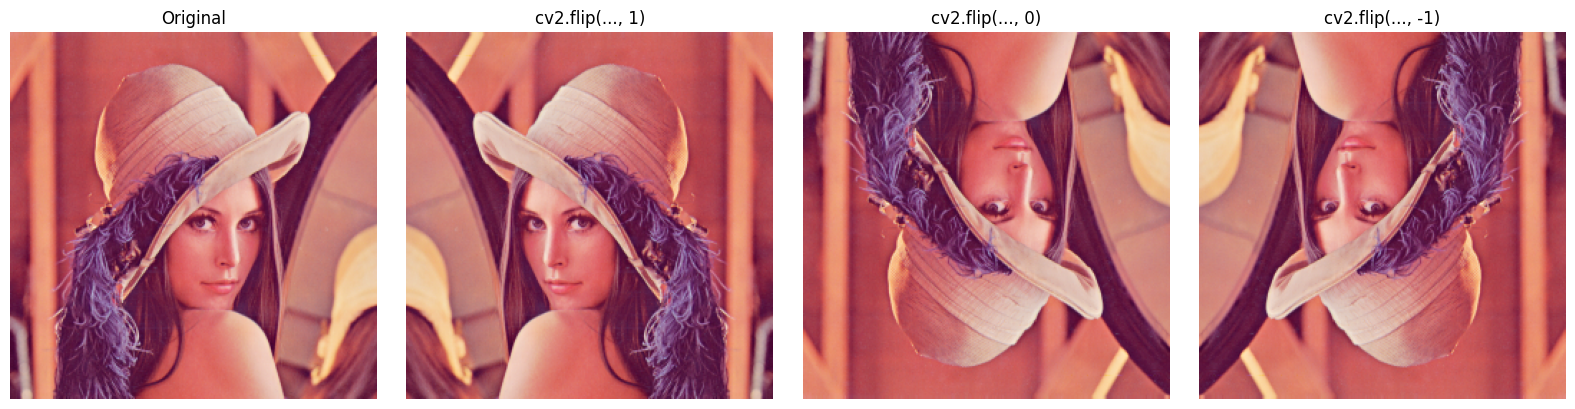

In [ ]:
# ตัวอย่าง cv2.flip() กับภาพสี RGB
cv_color_horizontal = cv2.flip(color_image, 1)
cv_color_vertical = cv2.flip(color_image, 0)
cv_color_both = cv2.flip(color_image, -1)

show_images(
    [color_image, cv_color_horizontal, cv_color_vertical, cv_color_both],
    ["Original", "cv2.flip(..., 1)", "cv2.flip(..., 0)", "cv2.flip(..., -1)"],
)

### ใช้ `cv2.transpose()`

`cv2.transpose(image)` สลับแถวกับคอลัมน์เหมือนฟังก์ชัน `transpose_image()` ที่เขียนไว้ก่อนหน้า รูปร่างจึงเปลี่ยนจาก `(H, W)` เป็น `(W, H)`

Grayscale: (512, 180) -> (180, 512)
RGB      : (256, 180, 3) -> (180, 256, 3)


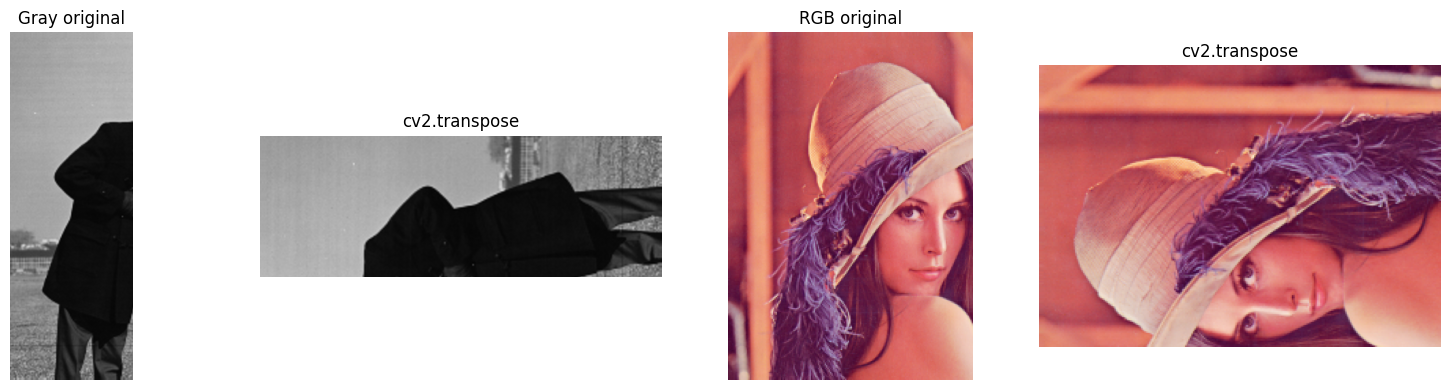

ผลจาก OpenCV ตรงกับฟังก์ชันที่เขียนเอง


In [ ]:
cv_gray_transposed = cv2.transpose(gray_rect)
cv_color_transposed = cv2.transpose(color_rect)

print("Grayscale:", gray_rect.shape, "->", cv_gray_transposed.shape)
print("RGB      :", color_rect.shape, "->", cv_color_transposed.shape)

show_images(
    [gray_rect, cv_gray_transposed, color_rect, cv_color_transposed],
    ["Gray original", "cv2.transpose", "RGB original", "cv2.transpose"],
)

# ตรวจผลกับฟังก์ชันที่เราเขียนเอง
assert np.array_equal(cv_gray_transposed, transpose_image(gray_rect))
assert np.array_equal(cv_color_transposed, transpose_image(color_rect))
print("ผลจาก OpenCV ตรงกับฟังก์ชันที่เขียนเอง")

## สรุป

- การกลับภาพเปลี่ยนตำแหน่งพิกเซล ไม่ได้เปลี่ยนค่าพิกเซล
- ใช้ `image.shape[:2]` และ `image[y, x]` เพื่อให้โค้ดเดียวรองรับทั้งภาพระดับเทาและภาพสี
- ซ้าย–ขวากลับลำดับคอลัมน์ ส่วนบน–ล่างกลับลำดับแถว
- Transpose สลับแกนแถวกับคอลัมน์ และทำให้ `(H, W)` เปลี่ยนเป็น `(W, H)`
- ในงานจริงใช้ NumPy slicing, `np.swapaxes()` หรือ `cv2.flip()` ได้ แต่ควรเข้าใจการจับคู่ตำแหน่งพิกเซลก่อน